# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Find nearest ocean point to each village to get sea ice or sst data

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load grid data

In [2]:
# set ocean/ice lat/lons - need to read in a separate grid file
dir_in_grid = '/glade/u/home/duvivier/masks/'
file_in = 'POP_tx0.1v3_grid.nc'
ds_grid = xr.open_dataset(dir_in_grid+file_in, decode_times=False)

# rename coordinates to those used in ice files
ds_grid = ds_grid.rename({'nlat': 'nj', 'nlon': 'ni'})
# clip global data to just Alaska
ds_grid_sub = ds_grid.isel(nj=slice(1700,2250)).isel(ni=slice(2700,3300))

lat2d = ds_grid_sub.TLAT
lon2d = ds_grid_sub.TLONG
land = ds_grid_sub.KMT

# need to convert the longitude to 0-360 instead of -180 to 180
lon2d = lon2d.where(lon2d >0, lon2d+360)

## Get nearest point to each village

### Set villages

In [3]:
# set paired lists with name and lat/lon
# main villages
village_names = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats =  [66.257, 64.501, 63.879, 63.694,63.776]
village_lons =  [-166.072, -165.406, -160.790, -170.479,-171.701]

nvillages = len(village_names)
print(nvillages)

5


### Find nearest grid cell

In [5]:
# First village - Savoonga
n = 3

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village_1 = village_lats[n]
lon_village_1 = village_lons[n] + 360

# First, find the index of the grid point nearest a specific lat/lon.   
abslat = np.abs(lat2d - lat_village_1)
abslon = np.abs(lon2d - lon_village_1)
c = np.maximum(abslon, abslat)

# find the smallest values
([xloc_1], [yloc_1]) = np.where(c == np.min(c))

# print initial index values
print(xloc_1,yloc_1)

lat_grid_1 = lat2d.isel(nj=xloc_1,ni=yloc_1).values
lon_grid_1 = lon2d.isel(nj=xloc_1,ni=yloc_1).values

# Check how close these are to the latitude and longitude of the village
print(village_names[n]+': '+str(lat_village_1)+','+str(lon_village_1))
print('grid point: '+str(lat_grid_1)+','+str(lon_grid_1))

Savoonga
238 234
Savoonga: 63.694,189.521
grid point: 63.727600402052815,189.49025119934447


In [6]:
# Second village - Gambell
n = 4

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village_2 = village_lats[n]
lon_village_2 = village_lons[n] + 360

# First, find the index of the grid point nearest a specific lat/lon.   
abslat = np.abs(lat2d - lat_village_2)
abslon = np.abs(lon2d - lon_village_2)
c = np.maximum(abslon, abslat)

# find the smallest values
([xloc_2], [yloc_2]) = np.where(c == np.min(c))

# print initial index values
print(xloc_2,yloc_2)

lat_grid_2 = lat2d.isel(nj=xloc_2,ni=yloc_2).values
lon_grid_2 = lon2d.isel(nj=xloc_2,ni=yloc_2).values

# Check how close these are to the latitude and longitude of the village
print(village_names[n]+': '+str(lat_village_2)+','+str(lon_village_2))
print('grid point: '+str(lat_grid_2)+','+str(lon_grid_2))

Gambell
237 224
Gambell: 63.776,188.299
grid point: 63.80622742262996,188.27806134687984


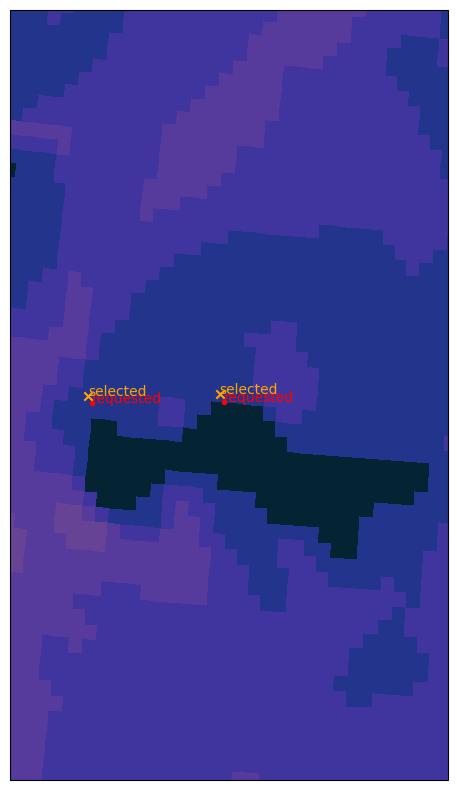

In [10]:
# Plot the Grid points to ensure we have the closest point for plots
fig = plt.figure(figsize=(10,10))

# make plot
ax = plt.subplot(1,1,1,projection = ccrs.NorthPolarStereo(central_longitude=180.0) )
ax.set_extent([lon_grid_1-1.5, lon_grid_1+1.5, lat_grid_1-1.5, lat_grid_1+1.5], crs=ccrs.PlateCarree())

# do a pcolormesh plot of input
cs0 = ax.pcolormesh(lon2d, lat2d, land, cmap = cmocean.cm.thermal, vmin = 0, vmax = 20, transform=ccrs.PlateCarree())

# do scatter plot of all grid values
#cs1 = ax.plot(lon2d, lat2d,land, c='white',marker='.', linestyle='none',transform=ccrs.PlateCarree())

## First Village - Savoonga
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_1, lat_village_1, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_1, lat_village_1, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon2d.isel(nj=xloc_1,ni=yloc_1), lat2d.isel(nj=xloc_1,ni=yloc_1), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon2d.isel(nj=xloc_1,ni=yloc_1), lat2d.isel(nj=xloc_1,ni=yloc_1), 'selected', c='orange', transform=ccrs.PlateCarree())

## Second Village - Gambell
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_2, lat_village_2, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_2, lat_village_2, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon2d.isel(nj=xloc_2,ni=yloc_2), lat2d.isel(nj=xloc_2,ni=yloc_2), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon2d.isel(nj=xloc_2,ni=yloc_2), lat2d.isel(nj=xloc_2,ni=yloc_2), 'selected', c='orange', transform=ccrs.PlateCarree())
          